In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime

In [2]:
df = pd.read_csv('./Time-Series-Analysis-Resources/6-Smooting_Techniques/data/us_airline_carrier_passenger.csv')
df.head()

,month,passengers
0,2000-01-01,46492
1,2000-02-01,48526
2,2000-03-01,58764
3,2000-04-01,56033
4,2000-05-01,58201


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   month       240 non-null    str  
 1   passengers  240 non-null    int64
dtypes: int64(1), str(1)
memory usage: 6.2 KB


In [4]:
df['month'] = pd.to_datetime(df['month'])
df.dtypes

month         datetime64[us]
passengers             int64
dtype: object

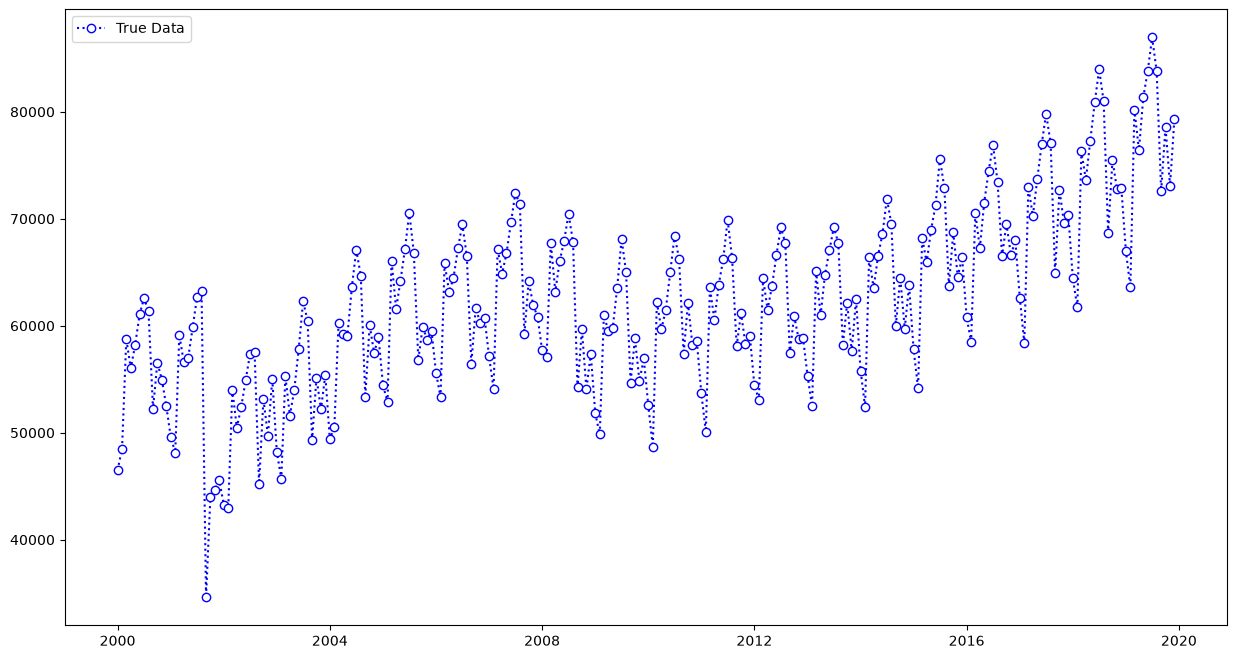

In [5]:
# visualization
plt.figure(figsize=(15,8))
plt.plot(df['month'],df['passengers'],'bo:',markerfacecolor='w')
plt.legend(['True Data'])

In [6]:
# train (upto dec 2016)
# test (rest)
df_train = df[df['month'] <= datetime.datetime.strptime('2016-12-01','%Y-%m-%d')]
df_train.tail()

,month,passengers
199,2016-08-01,73450
200,2016-09-01,66477
201,2016-10-01,69539
202,2016-11-01,66591
203,2016-12-01,67983


In [7]:
df_test = df[df['month'] > datetime.datetime.strptime('2016-12-01','%Y-%m-%d')]
df_test.head()

,month,passengers
204,2017-01-01,62621
205,2017-02-01,58377
206,2017-03-01,72962
207,2017-04-01,70262
208,2017-05-01,73679


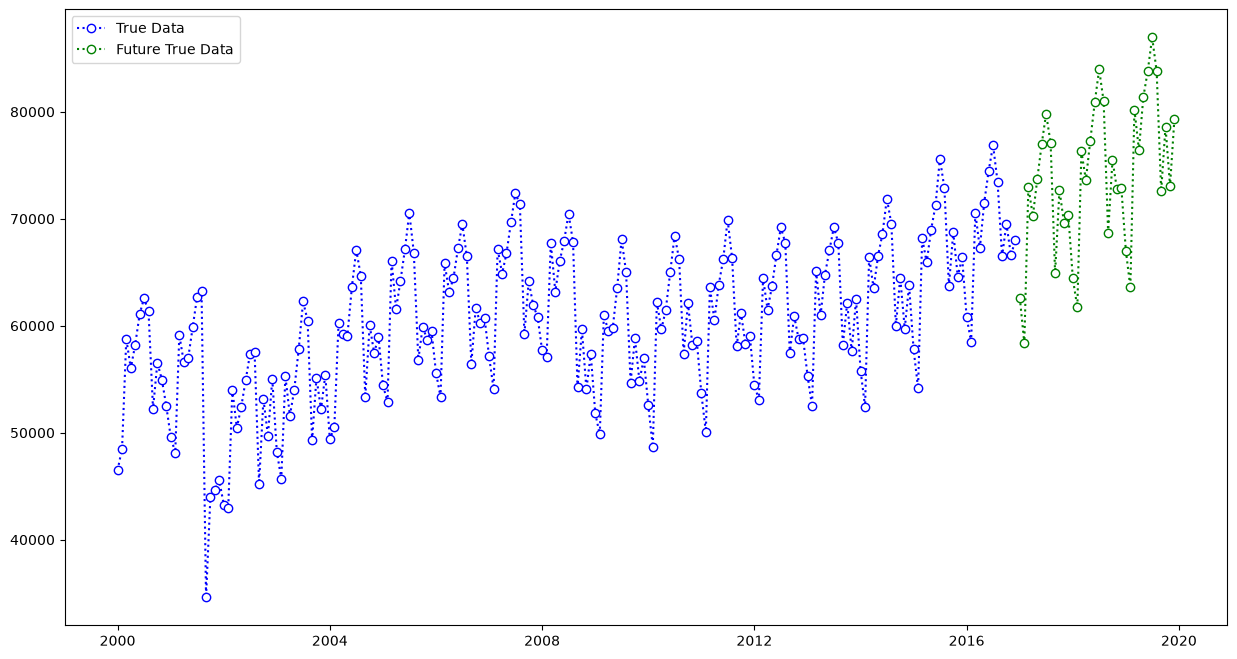

In [8]:
# visualization
plt.figure(figsize=(15,8))
plt.plot(df_train['month'],df_train['passengers'],'bo:',markerfacecolor='w')
plt.plot(df_test['month'],df_test['passengers'],'go:',markerfacecolor='w')
plt.legend(['True Data', 'Future True Data'])

### Naive Forecasting Model

> $ Y_{t+1} = Y_t$

In [9]:
df_train['fitted_values'] = df_train['passengers'].shift(1) # naive forecasting model
df_train.head()

,month,passengers,fitted_values
0,2000-01-01,46492,NaN
1,2000-02-01,48526,46492.0
2,2000-03-01,58764,48526.0
3,2000-04-01,56033,58764.0
4,2000-05-01,58201,56033.0


In [10]:
df_train.tail()

,month,passengers,fitted_values
199,2016-08-01,73450,76886.0
200,2016-09-01,66477,73450.0
201,2016-10-01,69539,66477.0
202,2016-11-01,66591,69539.0
203,2016-12-01,67983,66591.0


In [11]:
df_test['forecast'] = df_train['passengers'][len(df_train)-1] # naive forecasting model
df_test.head()

,month,passengers,forecast
204,2017-01-01,62621,67983
205,2017-02-01,58377,67983
206,2017-03-01,72962,67983
207,2017-04-01,70262,67983
208,2017-05-01,73679,67983


In [12]:
# margin of error
error = df_train['passengers'] - df_train['fitted_values']
me = 1.96*error.std() # 95% ME

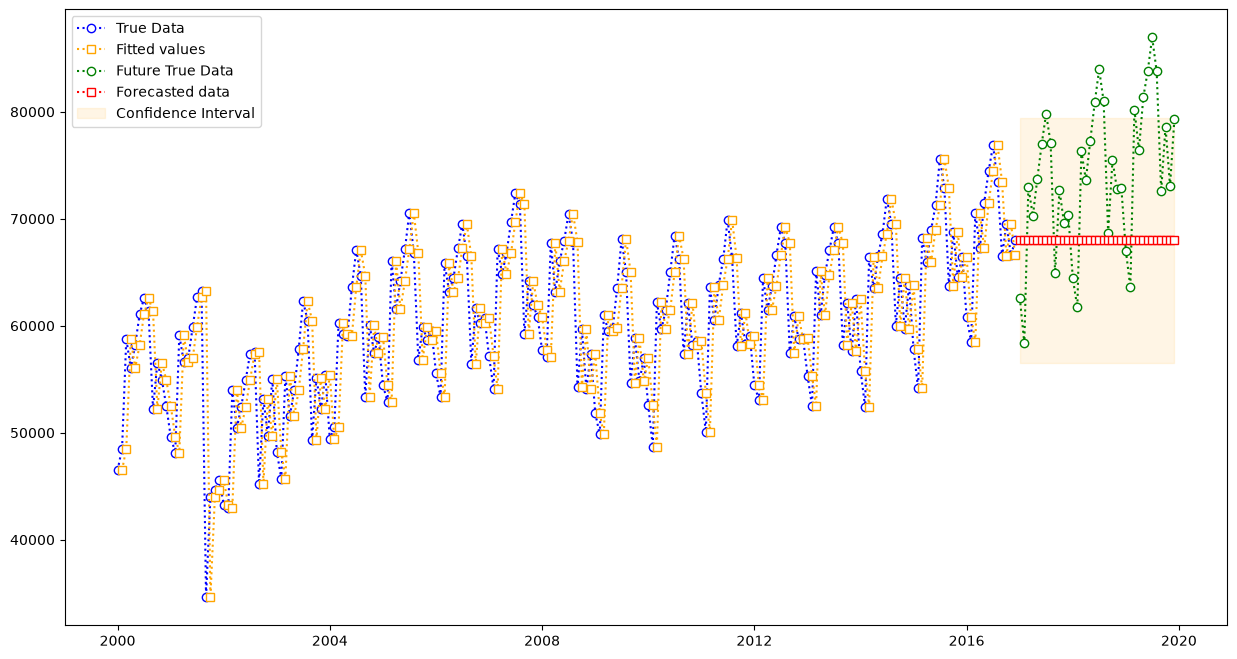

In [13]:
# visualization
plt.figure(figsize=(15,8))
plt.plot(df_train['month'],df_train['passengers'],'bo:',markerfacecolor='w')

# fitted values
plt.plot(df_train['month'],df_train['fitted_values'],'s:',color='orange',markerfacecolor='w')

plt.plot(df_test['month'],df_test['passengers'],'go:',markerfacecolor='w')

# forecasting
plt.plot(df_test['month'],df_test['forecast'],'s:',color='red',markerfacecolor='w')

# Fill Confidence Interval
plt.fill_between(df_test['month'], (df_test['forecast'] + me), (df_test['forecast'] - me), color='orange', alpha=0.1)

plt.legend(['True Data','Fitted values','Future True Data','Forecasted data','Confidence Interval'])
plt.show()

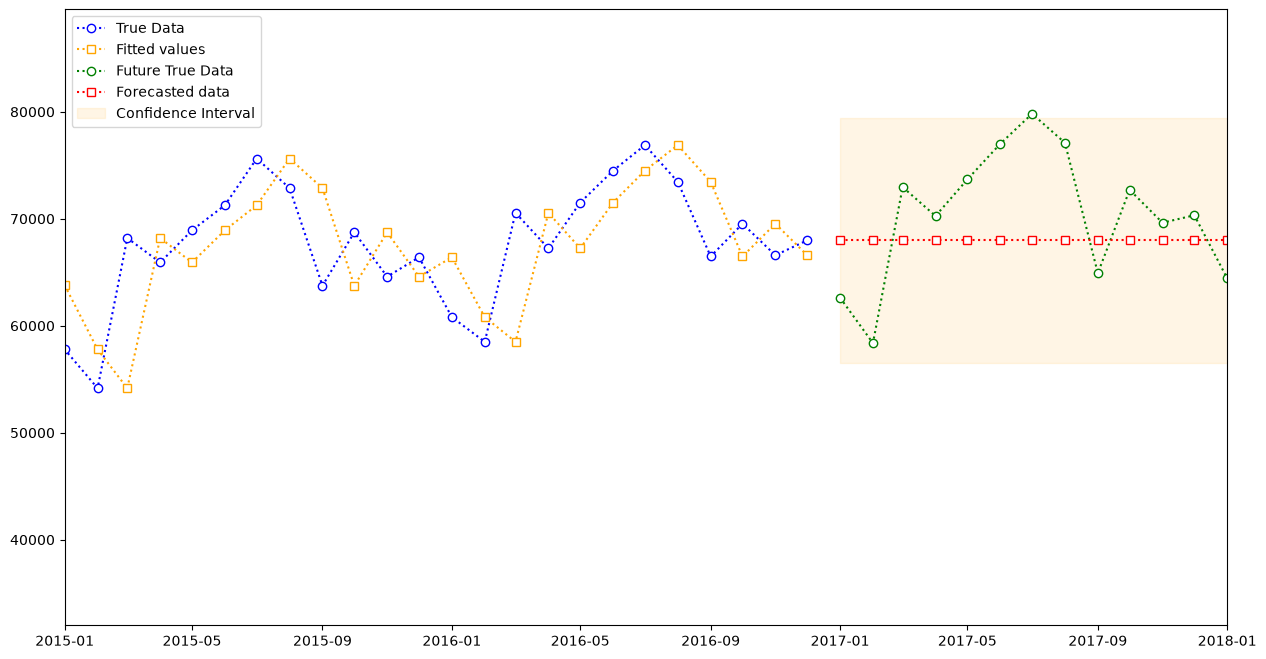

In [14]:
# visualization
plt.figure(figsize=(15,8))
plt.plot(df_train['month'],df_train['passengers'],'bo:',markerfacecolor='w')

# fitted values
plt.plot(df_train['month'],df_train['fitted_values'],'s:',color='orange',markerfacecolor='w')

plt.plot(df_test['month'],df_test['passengers'],'go:',markerfacecolor='w')

# forecasting
plt.plot(df_test['month'],df_test['forecast'],'s:',color='red',markerfacecolor='w')

# Fill Confidence Interval
plt.fill_between(df_test['month'], (df_test['forecast'] + me), (df_test['forecast'] - me), color='orange', alpha=0.1)

plt.legend(['True Data','Fitted values','Future True Data','Forecasted data','Confidence Interval'])

# scaling

start_date = datetime.datetime.strptime("2015-01-01",'%Y-%m-%d')
end_date = datetime.datetime.strptime("2018-01-01",'%Y-%m-%d')
plt.axis(xmin=start_date, xmax=end_date)
plt.show()


# Simple Moving Average

### MA(q)

- The most elementary of the averaging models is the simple average model.

- With this model, the forecast for time period t is the average of the values for a given number of previous time periods, as shown in the following equation.

$$
\hat{Y}_t = \frac{Y_{t-1} + Y_{t-2} + Y_{t-3} + \cdots + Y_{t-q}}{q}
$$

Where,

- $Y_t$ = Forecast value of the time period t

- $Y_{t-1}, Y_{t-2}, \ldots, Y_{t-q}$ are previous lag values.

- Order of $q$ is from ACF (number of non-zero lags).


In [15]:
df_train_sma = df_train[['month','passengers']].copy()
df_test_sma = df_test[['month','passengers']].copy()

### SMA(3)

In [16]:
df_train_sma['fitted_3'] = df_train_sma['passengers'].rolling(window=3).mean() # mean,median,std,var etc. can also be used
df_train_sma.head()

,month,passengers,fitted_3
0,2000-01-01,46492,NaN
1,2000-02-01,48526,NaN
2,2000-03-01,58764,51260.666667
3,2000-04-01,56033,54441.000000
4,2000-05-01,58201,57666.000000


In [17]:
df_train_sma.tail()

,month,passengers,fitted_3
199,2016-08-01,73450,74946.000000
200,2016-09-01,66477,72271.000000
201,2016-10-01,69539,69822.000000
202,2016-11-01,66591,67535.666667
203,2016-12-01,67983,68037.666667


In [18]:
df_test_sma['forecast'] = df_train_sma['fitted_3'][len(df_train_sma)-1]

In [19]:
df_test_sma.head()

,month,passengers,forecast
204,2017-01-01,62621,68037.666667
205,2017-02-01,58377,68037.666667
206,2017-03-01,72962,68037.666667
207,2017-04-01,70262,68037.666667
208,2017-05-01,73679,68037.666667


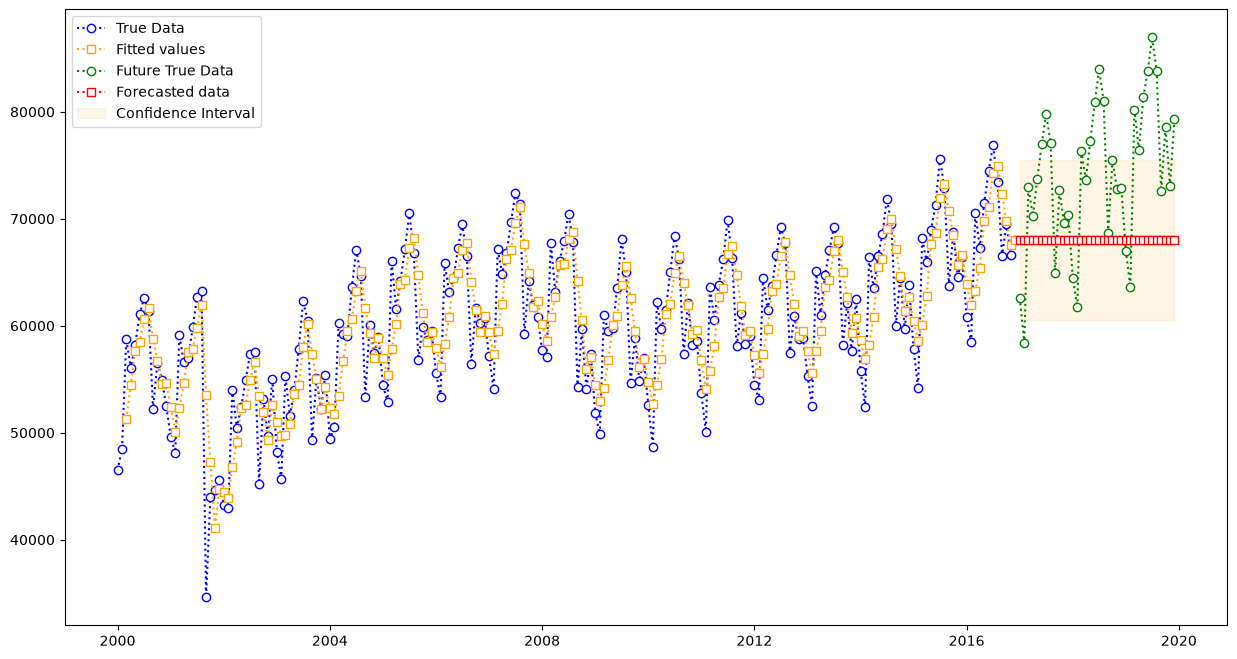

In [20]:
# margin of error
error_3 = df_train_sma['passengers'] - df_train_sma['fitted_3']
me_3 = 1.96*error_3.std() # 95% ME
# visualization
plt.figure(figsize=(15,8))
plt.plot(df_train_sma['month'],df_train_sma['passengers'],'bo:',markerfacecolor='w')

# fitted values
plt.plot(df_train_sma['month'],df_train_sma['fitted_3'],'s:',color='orange',markerfacecolor='w')

plt.plot(df_test_sma['month'],df_test_sma['passengers'],'go:',markerfacecolor='w')

# forecasting
plt.plot(df_test_sma['month'],df_test_sma['forecast'],'s:',color='red',markerfacecolor='w')

# Fill Confidence Interval
plt.fill_between(df_test_sma['month'], (df_test_sma['forecast'] + me_3), (df_test_sma['forecast'] - me_3), color='orange', alpha=0.1)

plt.legend(['True Data','Fitted values','Future True Data','Forecasted data','Confidence Interval'])

# scaling

# start_date = datetime.datetime.strptime("2015-01-01",'%Y-%m-%d')
# end_date = datetime.datetime.strptime("2018-01-01",'%Y-%m-%d')
# plt.axis(xmin=start_date, xmax=end_date)
plt.show()

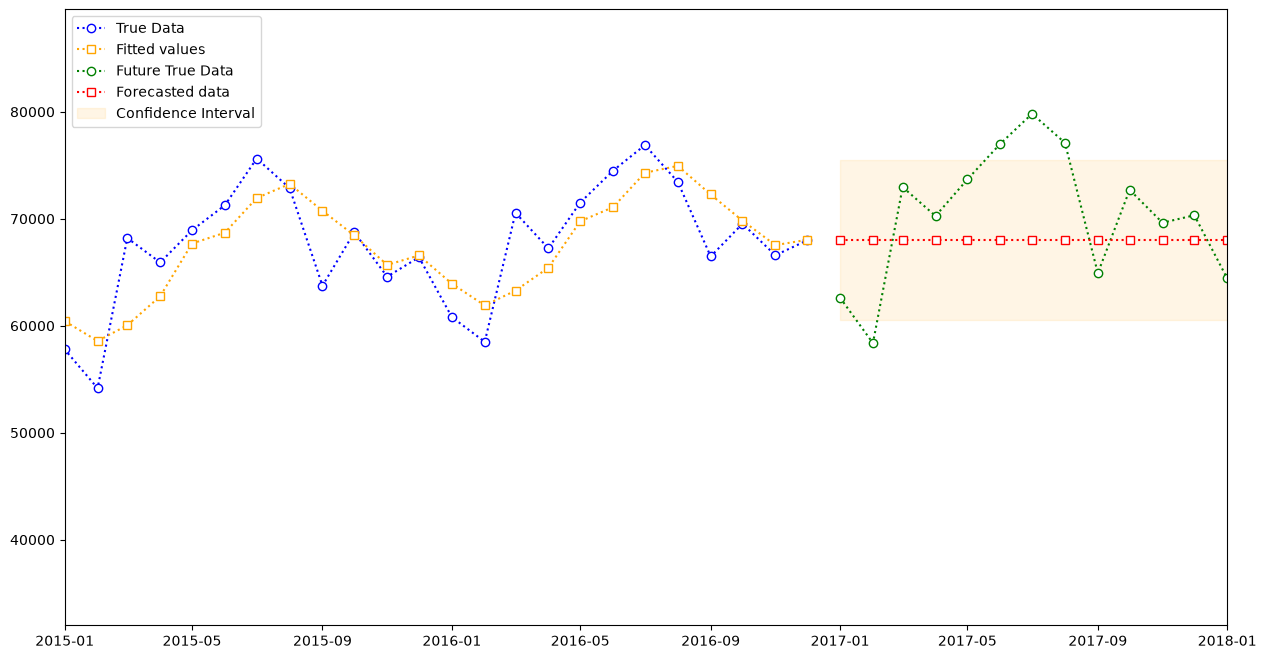

In [21]:
# margin of error
error_3 = df_train_sma['passengers'] - df_train_sma['fitted_3']
me_3 = 1.96*error_3.std() # 95% ME
# visualization
plt.figure(figsize=(15,8))
plt.plot(df_train_sma['month'],df_train_sma['passengers'],'bo:',markerfacecolor='w')

# fitted values
plt.plot(df_train_sma['month'],df_train_sma['fitted_3'],'s:',color='orange',markerfacecolor='w')

plt.plot(df_test_sma['month'],df_test_sma['passengers'],'go:',markerfacecolor='w')

# forecasting
plt.plot(df_test_sma['month'],df_test_sma['forecast'],'s:',color='red',markerfacecolor='w')

# Fill Confidence Interval
plt.fill_between(df_test_sma['month'], (df_test_sma['forecast'] + me_3), (df_test_sma['forecast'] - me_3), color='orange', alpha=0.1)

plt.legend(['True Data','Fitted values','Future True Data','Forecasted data','Confidence Interval'])

# scaling

start_date = datetime.datetime.strptime("2015-01-01",'%Y-%m-%d')
end_date = datetime.datetime.strptime("2018-01-01",'%Y-%m-%d')
plt.axis(xmin=start_date, xmax=end_date)
plt.show()

# SMA (q)
-> q ACF

In [22]:
from statsmodels.graphics.tsaplots import plot_acf

In [23]:
difference = df_train_sma['passengers'].diff(1)

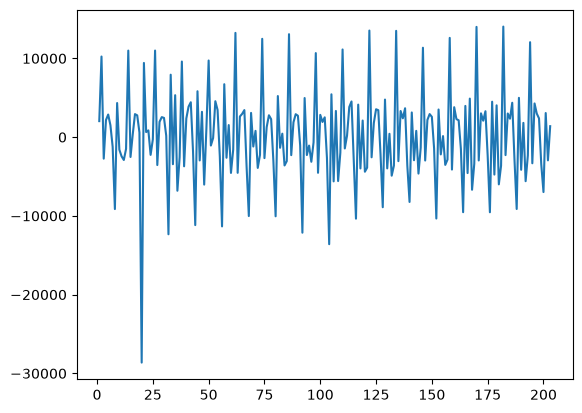

In [24]:
plt.plot(difference)

In [25]:
# remove the missing values
difference.dropna(inplace=True)

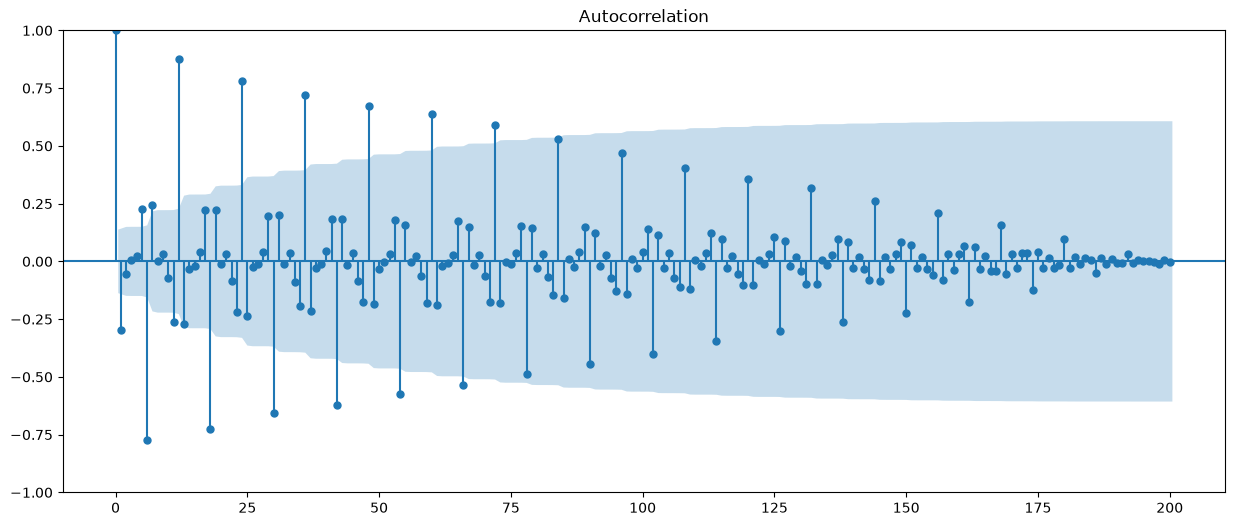

In [26]:
fig,ax = plt.subplots(figsize=(15,6))
fig = plot_acf(difference,lags=200,ax=ax)

**According to acf we need to select at least 62 lags to forecast the future**

In [27]:
df_train_sma['fitted_62'] = df_train_sma['passengers'].rolling(window=62).mean()

In [28]:
df_train_sma.tail()

,month,passengers,fitted_3,fitted_62
199,2016-08-01,73450,74946.000000,63984.967742
200,2016-09-01,66477,72271.000000,63929.580645
201,2016-10-01,69539,69822.000000,63981.838710
202,2016-11-01,66591,67535.666667,64119.306452
203,2016-12-01,67983,68037.666667,64228.661290


In [29]:
df_test_sma['forecast_62'] = 64228.661290

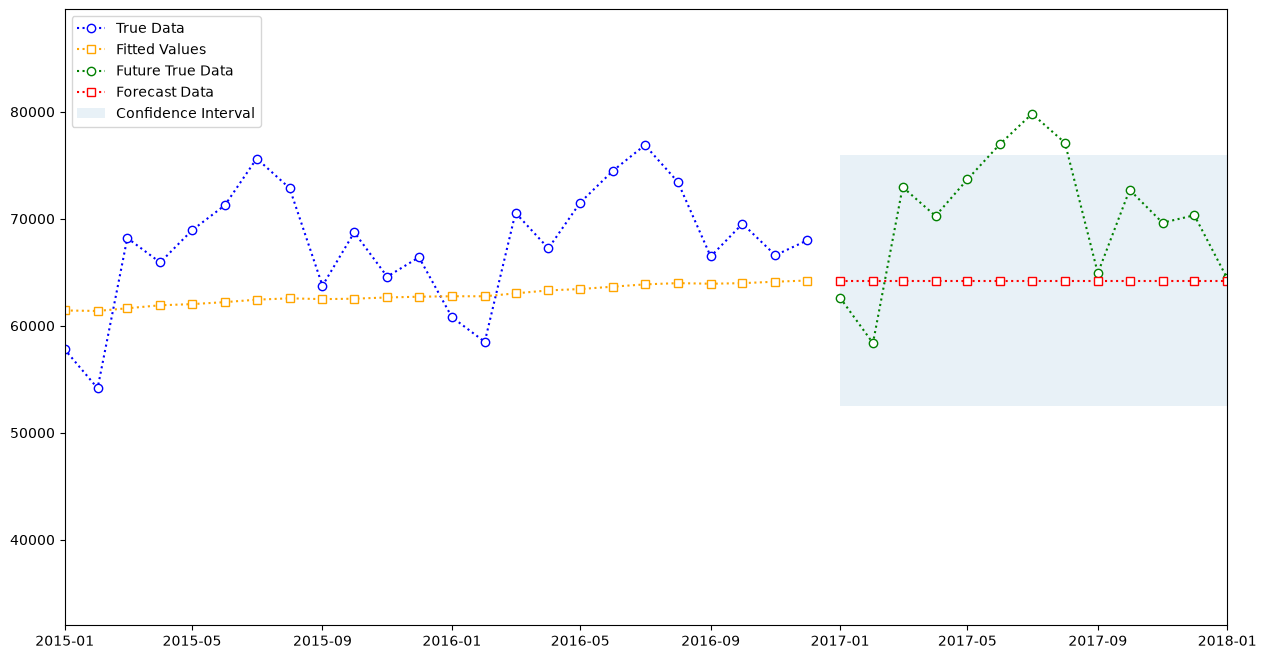

In [30]:
# margin of error
error_62 = df_train_sma['passengers'] - df_train_sma['fitted_62']
me_62 = 1.96*error_62.std() # 95% ME
# visualzation
plt.figure(figsize=(15,8))
plt.plot(df_train_sma['month'],df_train_sma['passengers'],'bo:',markerfacecolor='w')
# fitted values
plt.plot(df_train_sma['month'],df_train_sma['fitted_62'],'s:',color='orange',markerfacecolor='w')


plt.plot(df_test_sma['month'],df_test_sma['passengers'],'go:',markerfacecolor='w')
# forecasting
plt.plot(df_test_sma['month'],df_test_sma['forecast_62'],'s:',color='red',markerfacecolor='w')

# Fill confidence interval
plt.fill_between(df_test_sma['month'],(df_test_sma['forecast_62']+me_62),(df_test_sma['forecast_62']-me_62),alpha=0.1)
plt.legend(['True Data','Fitted Values','Future True Data','Forecast Data','Confidence Interval'])
# scalling
start_date = datetime.datetime.strptime("2015-01-01","%Y-%m-%d")
end_date = datetime.datetime.strptime("2018-01-01","%Y-%m-%d")
plt.axis(xmin=start_date,
         xmax=end_date)
plt.show()

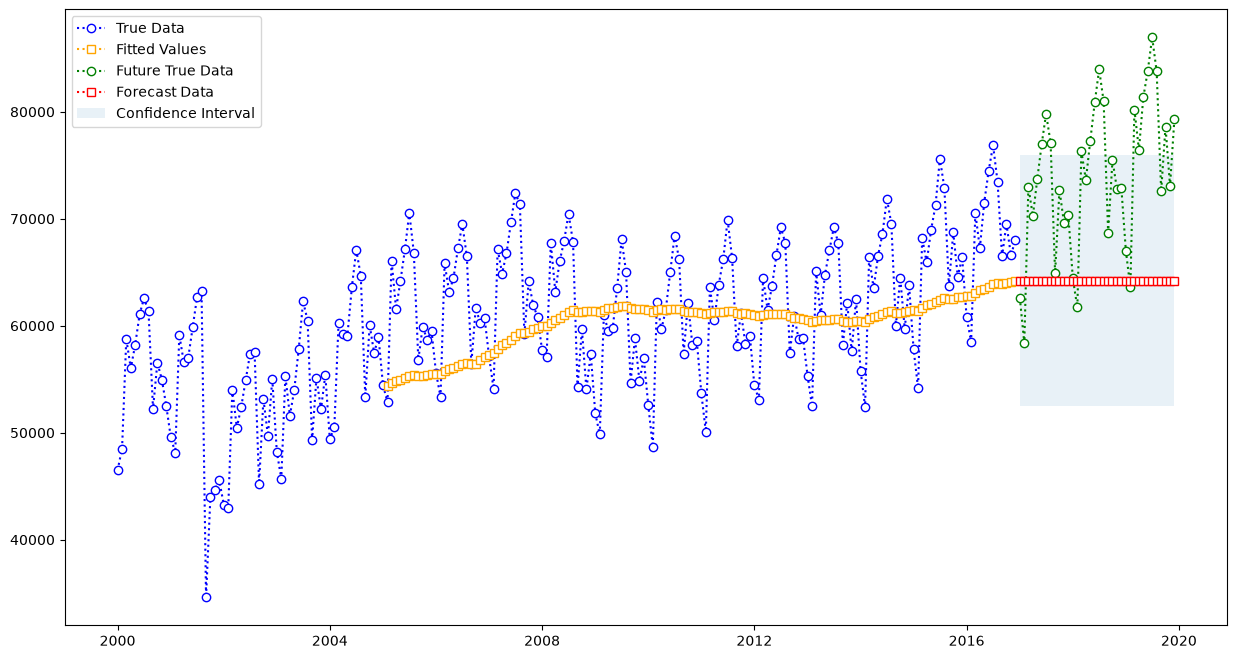

In [31]:
# margin of error
error_62 = df_train_sma['passengers'] - df_train_sma['fitted_62']
me_62 = 1.96*error_62.std() # 95% ME
# visualzation
plt.figure(figsize=(15,8))
plt.plot(df_train_sma['month'],df_train_sma['passengers'],'bo:',markerfacecolor='w')
# fitted values
plt.plot(df_train_sma['month'],df_train_sma['fitted_62'],'s:',color='orange',markerfacecolor='w')


plt.plot(df_test_sma['month'],df_test_sma['passengers'],'go:',markerfacecolor='w')
# forecasting
plt.plot(df_test_sma['month'],df_test_sma['forecast_62'],'s:',color='red',markerfacecolor='w')

# Fill confidence interval
plt.fill_between(df_test_sma['month'],(df_test_sma['forecast_62']+me_62),(df_test_sma['forecast_62']-me_62),alpha=0.1)
plt.legend(['True Data','Fitted Values','Future True Data','Forecast Data','Confidence Interval'])
# scalling
# start_date = datetime.datetime.strptime("2015-01-01","%Y-%m-%d")
# end_date = datetime.datetime.strptime("2018-01-01","%Y-%m-%d")
# plt.axis(xmin=start_date,
#          xmax=end_date)
plt.show()


# Weighted Moving Average

- A forecaster may want to place more weight on certain periods of time than on others.

- For example, a forecaster might believe that the previous month's value is three times as important in forecasting as other months.

- A moving average in which some time periods are weighted differently than others is called a **weighted moving average**.

### Mathematical Equation

$$
\hat{Y}_t =
\frac{
q * Y_{t-1} + (q-1) * Y_{t-2} + (q-2) * Y_{t-3} + \cdots + Y_{t-q}
}{
q + (q-1) + (q-2) + \cdots + 1
}
$$

### Where:

- $Y_t$ = Forecast value of the time period t

- $Y_{t-1}, Y_{t-2}, \ldots, Y_{t-q}$ are previous lag values.

- $q$ = Number of lags


In [32]:
df_train_wma = df_train[['month','passengers']]
df_test_wma = df_test[['month','passengers']]

In [33]:
df_train_wma.head()

,month,passengers
0,2000-01-01,46492
1,2000-02-01,48526
2,2000-03-01,58764
3,2000-04-01,56033
4,2000-05-01,58201


### WMA(3)

In [34]:
def weighted_moving_average(x):
    # x is a numpy array
    # generate weights
    #print(x)
    weights = np.arange(1,len(x)+1,1)
    #print(weights)
    num = np.sum(x*weights)
    den = np.sum(weights)
    wma = num/den
    return wma


In [35]:
sample = df_train_wma.head()
sample


,month,passengers
0,2000-01-01,46492
1,2000-02-01,48526
2,2000-03-01,58764
3,2000-04-01,56033
4,2000-05-01,58201


In [36]:
sample['passengers'].rolling(window=3).apply(weighted_moving_average)

0             NaN
1             NaN
2    53306.000000
3    55692.166667
4    57572.166667
Name: passengers, dtype: float64

In [37]:
# applying to entire data
df_train_wma['fitted_wma_3'] = df_train_wma['passengers'].rolling(window=3).apply(weighted_moving_average)
df_train_wma['fitted_wma_62'] = df_train_wma['passengers'].rolling(window=62).apply(weighted_moving_average)

In [38]:
df_train_wma.tail()

,month,passengers,fitted_wma_3,fitted_wma_62
199,2016-08-01,73450,74770.666667,65520.943164
200,2016-09-01,66477,70536.166667,65600.055300
201,2016-10-01,69539,69170.166667,65778.132104
202,2016-11-01,66591,67554.666667,65860.962622
203,2016-12-01,67983,67778.333333,65983.619560


In [39]:
df_test_wma['forecast_3'] = df_train_wma['fitted_wma_3'][len(df_train_wma)-1]
df_test_wma['forecasted_62'] = df_train_wma['fitted_wma_62'][len(df_train_wma)-1]

In [40]:
df_test_wma.head()

,month,passengers,forecast_3,forecasted_62
204,2017-01-01,62621,67778.333333,65983.61956
205,2017-02-01,58377,67778.333333,65983.61956
206,2017-03-01,72962,67778.333333,65983.61956
207,2017-04-01,70262,67778.333333,65983.61956
208,2017-05-01,73679,67778.333333,65983.61956


**Plot with 62 lags**

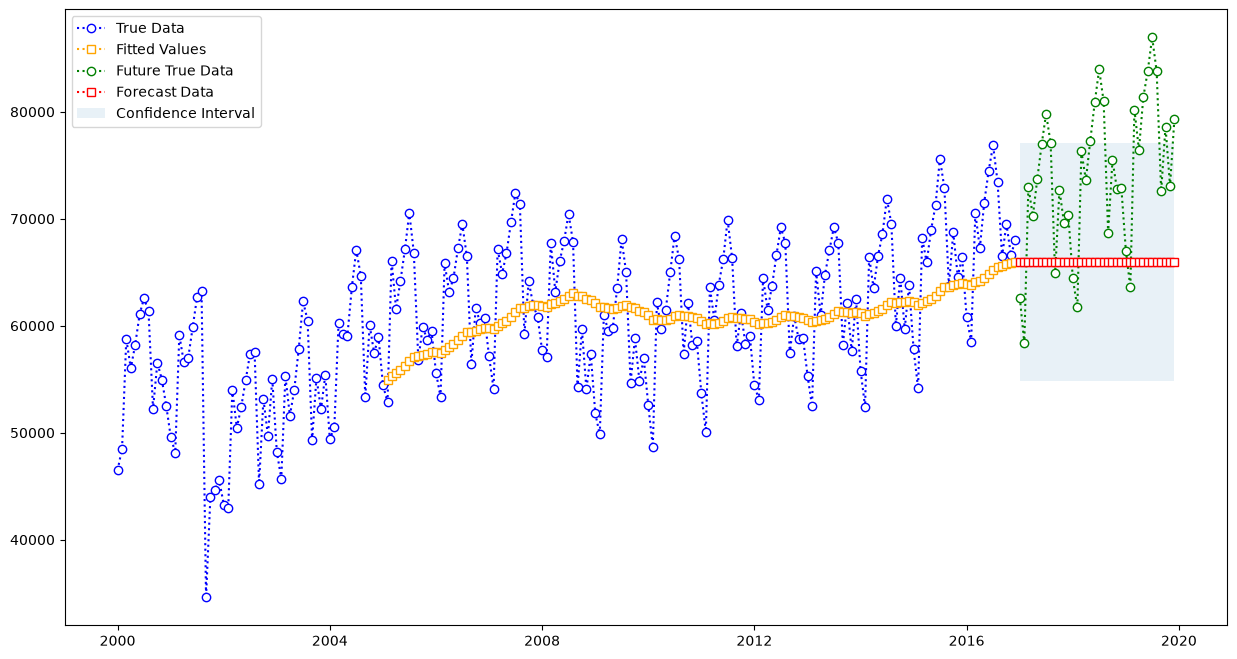

In [41]:
# margin of error
error_62 = df_train_wma['passengers'] - df_train_wma['fitted_wma_62']
me_62 = 1.96*error_62.std() # 95% ME

# visualization
plt.figure(figsize=(15,8))
plt.plot(df_train_wma['month'],df_train_wma['passengers'],'bo:',markerfacecolor='w')

# fitted values
plt.plot(df_train_wma['month'],df_train_wma['fitted_wma_62'],'s:',color='orange',markerfacecolor='w')


plt.plot(df_test_wma['month'],df_test_wma['passengers'],'go:',markerfacecolor='w')

# forecasting
plt.plot(df_test_wma['month'],df_test_wma['forecasted_62'],'s:',color='red',markerfacecolor='w')

# Fill confidence interval
plt.fill_between(df_test_wma['month'],(df_test_wma['forecasted_62']+me_62),(df_test_wma['forecasted_62']-me_62),alpha=0.1)
plt.legend(['True Data','Fitted Values','Future True Data','Forecast Data','Confidence Interval'])

# scalling
# start_date = datetime.datetime.strptime("2015-01-01","%Y-%m-%d")
# end_date = datetime.datetime.strptime("2018-01-01","%Y-%m-%d")
# plt.axis(xmin=start_date,
#          xmax=end_date)

plt.show()


In [42]:
df_train_ema = df_train[['month','passengers']].copy()
df_test_ema = df_test[['month','passengers']].copy()

In [43]:
# ema
df_train_ema['fitted_3'] = df_train_ema['passengers'].ewm(min_periods=3,alpha=0.5).mean()

In [44]:
df_train_ema.head()

,month,passengers,fitted_3
0,2000-01-01,46492,NaN
1,2000-02-01,48526,NaN
2,2000-03-01,58764,54085.714286
3,2000-04-01,56033,55124.266667
4,2000-05-01,58201,56712.258065


In [45]:
df_train_ema.tail()

,month,passengers,fitted_3
199,2016-08-01,73450,73886.632073
200,2016-09-01,66477,70181.816036
201,2016-10-01,69539,69860.408018
202,2016-11-01,66591,68225.704009
203,2016-12-01,67983,68104.352005


In [46]:
# forecast = last fitted EMA value from training data, applied to the test period
df_test_ema['forecast_3_0.5'] = df_train_ema['fitted_3'].iloc[-1]
df_test_ema.head()

,month,passengers,forecast_3_0.5
204,2017-01-01,62621,68104.352005
205,2017-02-01,58377,68104.352005
206,2017-03-01,72962,68104.352005
207,2017-04-01,70262,68104.352005
208,2017-05-01,73679,68104.352005


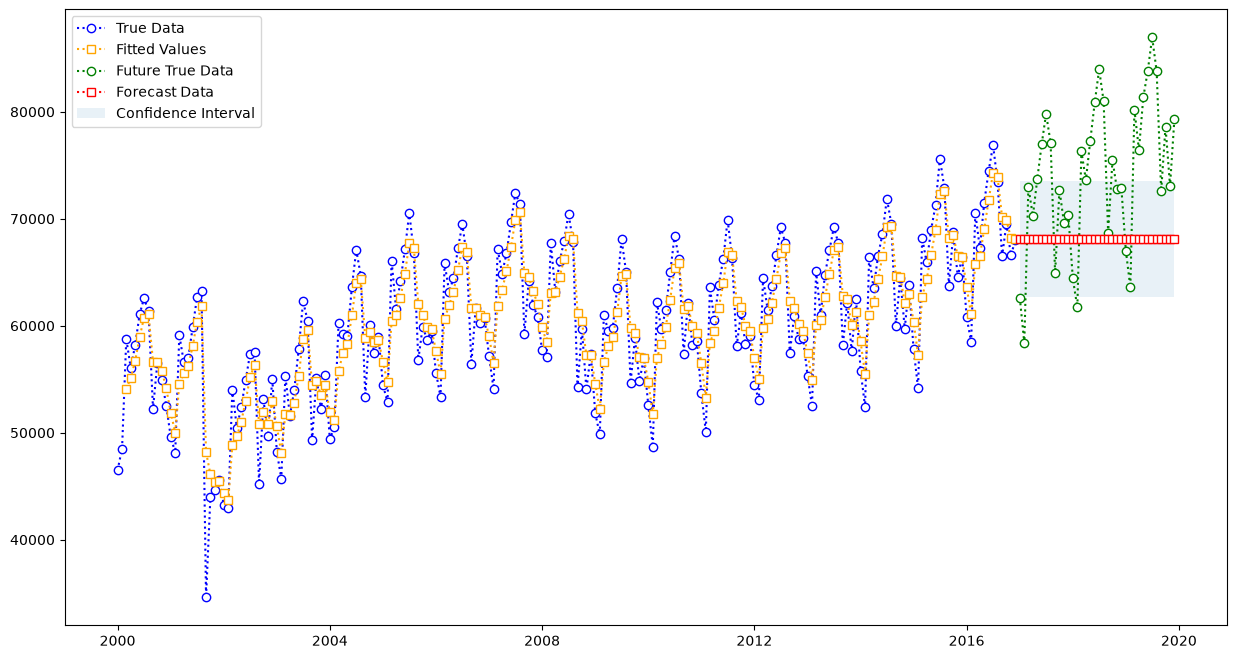

In [47]:

# margin of error
error_0_3 = df_train_ema['passengers'] - df_train_ema['fitted_3']
me_0_3 = 1.96*error_0_3.std() # 95% ME

# visualization
plt.figure(figsize=(15,8))
plt.plot(df_train_ema['month'],df_train_ema['passengers'],'bo:',markerfacecolor='w')

# fitted values
plt.plot(df_train_ema['month'],df_train_ema['fitted_3'],'s:',color='orange',markerfacecolor='w')


plt.plot(df_test_ema['month'],df_test_ema['passengers'],'go:',markerfacecolor='w')

# forecasting
plt.plot(df_test_ema['month'],df_test_ema['forecast_3_0.5'],'s:',color='red',markerfacecolor='w')


# Fill confidence interval
plt.fill_between(df_test_ema['month'],(df_test_ema['forecast_3_0.5']+me_0_3),
                 (df_test_ema['forecast_3_0.5']-me_0_3),alpha=0.1)

plt.legend(['True Data','Fitted Values','Future True Data','Forecast Data','Confidence Interval'])

# scalling
# start_date = datetime.datetime.strptime("2015-01-01","%Y-%m-%d")
# end_date = datetime.datetime.strptime("2018-01-01","%Y-%m-%d")
# plt.axis(xmin=start_date,
#          xmax=end_date)

plt.show()
